# TP-2 — TinyGPT: instruction tuning y LoRA

Autor: Msc. Abraham R.

Vas a tomar el TinyGPT que preentrenaste en el TP-1 y enseñarle a seguir instrucciones, y
después fine-tunearlo en dos direcciones.

## Del preentrenamiento al fine-tuning

El TP-1 te dejó un modelo que continúa a Shakespeare. No puede seguir una instrucción, porque
nada en sus datos de entrenamiento se pareció nunca a una. El preentrenamiento y el
fine-tuning corren la misma loss sobre la misma arquitectura; cambian cuatro cosas:

| | Preentrenamiento | Fine-tuning |
|---|---|---|
| Datos | texto crudo, miles de millones de tokens | pares curados, miles |
| Loss | todos los tokens | **solo los tokens de la respuesta** |
| Learning rate | alto | 1-2 órdenes de magnitud más bajo |
| Formato | ninguno | un template con tokens especiales |

Esta es la etapa de supervised fine-tuning (SFT) detrás de modelos que siguen instrucciones,
como:
- InstructGPT / ChatGPT
- Llama-2-Chat
- Alpaca, y los muchos adapters LoRA construidos sobre modelos abiertos

**Parte 1 — Supervised fine-tuning.** Armá un dataset de instrucciones, envolvelo en un chat
template, y fine-tuneá todos los parámetros. La loss supervisada ve solo la respuesta.

**Parte 2 — Fine-tuning eficiente en parámetros.** Reemplazá el fine-tuning completo por
**LoRA**, y medí qué le costó cada fine-tune al modelo en lo que ya sabía.

El modelo base es el del TP-1 y no cambia: cada consigna fine-tunea una copia de él.

## Consignas

**Parte 1**
- Consigna I — armar el dataset de SFT con **prompt loss masking**.
- Consigna II — fine-tuning completo, y evaluación.

**Parte 2**
- Consigna III — implementar **LoRA** desde cero y compararlo contra el fine-tuning completo.
- Consigna IV — medir el **olvido catastrófico** sobre la distribución de preentrenamiento.

**Después**
- Consigna V — portar tu `generateV2` del TP-1 a una función de **chat**.
- Consigna VI — leer la **atención** en la posición de la respuesta.
- *Opcional* — mostrar que el preentrenamiento sirvió de algo.

## Cómo trabajar en esto

**Requisitos previos:** el TP-1 incluyendo la **Consigna X (un tokenizer de verdad)** — este
notebook carga `./checkpoints/tp1_subword/checkpoint_final.pt`, y preentrena su propio modelo
base si ese archivo no está.

La Consigna I viene con una celda `check_dataset()`, y la celda de LoRA verifica que el
modelo adaptado arranque idéntico a la base. Corrélas antes de entrenar — cuestan segundos y
atrapan los bugs que si no aparecerían como una curva de loss plana después de todo el
fine-tune.

**Conservá `./checkpoints/`.** El TP-3 continúa desde el modelo que fine-tuneás acá en vez de
entrenar uno nuevo. Los checkpoints no se entregan — pero si los borrás, vas a tener que
reentrenar.

Referencias: [LoRA](https://arxiv.org/abs/2106.09685) ·
[InstructGPT](https://arxiv.org/abs/2203.02155) · [PEFT](https://huggingface.co/docs/peft)

In [1]:
import copy
import math
import os
import random
import re
from collections import Counter
from typing import Dict, List, Optional, Tuple

from transformers import AutoTokenizer

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR, StepLR
from torch.utils.data import DataLoader, Dataset

from tinygpt import (
    CharDataset,
    GPTConfig,
    TinyGPT,
    count_parameters,
    describe,
    generate,
    get_device,
    load_checkpoint,
    load_tinyshakespeare,
    plot_losses,
    run_training,
    trim_kv_cache,
)
from trainer import Trainer

torch.manual_seed(1337)
random.seed(1337)

device = get_device()
print(f"dispositivo: {device}")

dispositivo: mps


# Etapa 0 — el modelo base preentrenado

Mismo corpus, mismo tokenizer y misma config que el TP-1, así que el checkpoint del TP-1 entra directo.

In [2]:
PRETRAIN_CHARS = 100_000    # exactamente lo que preentrenó el TP-1 -- fijo, para que la Consigna IV siga siendo comparable
NUM_WORKERS = 0
TP1_CKPT = "./checkpoints/tp1_subword/checkpoint_final.pt"

# El modelo base es el del TP-1 y no cambia: misma arquitectura, mismo tokenizer, los
# mismos 100k caracteres. Lo único que este notebook *puede* escalar es el fine-tune, así
# que las palabras de las instrucciones se extraen del corpus entero mientras que los datos
# de modelado de lenguaje se quedan con la porción sobre la que el checkpoint se entrenó.
sft_text = load_tinyshakespeare(None)
text = sft_text[:PRETRAIN_CHARS]

# El mismo tokenizer con el que preentrenó la Consigna X del TP-1, así que su checkpoint entra directo.
tokenizer = AutoTokenizer.from_pretrained("gpt2")
base_vocab_size = len(tokenizer)

# tie_weights=False: los checkpoints del TP-1 mantienen token_emb y head como dos matrices
# separadas. load_checkpoint se niega a cargarlas en un modelo con pesos atados en vez de
# descartar una de las dos en silencio.
config = GPTConfig(vocab_size=base_vocab_size, tie_weights=False)
data = torch.tensor(tokenizer(text, add_special_tokens=False)["input_ids"], dtype=torch.long)
split = int(0.9 * len(data))

# Guardado para la Consigna IV: la distribución de preentrenamiento sobre la que vamos a medir el olvido.
shakespeare_val_loader = DataLoader(CharDataset(data[split:], config.block_size),
                                   batch_size=config.batch_size, shuffle=False,
                                   drop_last=True, num_workers=NUM_WORKERS)

print(config)
print(f"porción preentrenada {len(text):>9,} chars -> {len(data):,} tokens "
      f"({len(text) / len(data):.2f} chars/token)")
print(f"corpus SFT           {len(sft_text):>9,} chars")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (30645 > 1024). Running this sequence through the model will result in indexing errors


GPTConfig(block_size=32, batch_size=64, n_embd=64, n_head=4, n_layer=2, dropout=0.1, vocab_size=50257, bias=True, tie_weights=False, ff_class=None, moe_args=None)
porción preentrenada   100,000 chars -> 30,645 tokens (3.26 chars/token)
corpus SFT           1,115,394 chars


In [3]:
base_model = TinyGPT(config).to(device)

if os.path.exists(TP1_CKPT):
    # load_checkpoint tolera el prefijo "_orig_mod." que una corrida en CUDA con
    # torch.compile deja en cada clave.
    load_checkpoint(base_model, TP1_CKPT, map_location=device)
    print(f"pesos preentrenados cargados desde {TP1_CKPT}")
else:
    print("no se encontró el checkpoint de la Consigna X del TP-1, se preentrena desde cero")
    print("(corré primero la Consigna X del TP-1 si querés exactamente el mismo modelo base)")
    pretrain_loader = DataLoader(CharDataset(data[:split], config.block_size),
                                 batch_size=config.batch_size, shuffle=True,
                                 drop_last=True, num_workers=NUM_WORKERS)
    opt = AdamW(base_model.parameters(), lr=1e-3)
    trainer = Trainer(model=base_model, train_data_loader=pretrain_loader,
                      test_data_loader=shakespeare_val_loader,
                      loss_fn=torch.nn.CrossEntropyLoss(), gradient_accumulation_steps=1,
                      optimizer=opt, scheduler=StepLR(opt, step_size=100, gamma=0.9),
                      device=device, save_dir="./checkpoints/tp2_base", save_every_n=500)
    run_training(trainer, epochs=2)

describe(base_model, "modelo base")

pesos preentrenados cargados desde ./checkpoints/tp1_subword/checkpoint_final.pt
modelo base: 6,535,040 parameters | 6,535,040 trainable (100.00%)


## Qué está representando esto

El método es el real; la escala y los datos no.

| | este notebook | un pipeline real |
|---|---|---|
| preentrenamiento | 100k caracteres de un solo dramaturgo | 10^12+ tokens, meses de GPU |
| datos de SFT | ~29k pares de un solo corpus | 10^4–10^6 pares curados, muchas veces escritos por humanos |
| etapas | preentrenamiento → SFT | preentrenamiento → SFT → preference tuning (RLHF / DPO / GRPO) |
| evaluación | exact match + condicionamiento | suites de benchmarks, preferencia humana, LLM-as-judge |

Idéntico en las dos escalas: la loss, el enmascarado del prompt, el resize del embedding, la
factorización de LoRA y el trade-off del olvido. Esas son las partes transferibles.

**Ajustá tus expectativas.** 6.5M de parámetros preentrenados sobre 30.645 tokens no van a
escribir buen Shakespeare — `continue` devuelve cosas como `",\nAnd I'll be not, and I am,"`.
Ese es el resultado correcto a esta escala, no un error tuyo. Juzgá la corrida por las
métricas — ¿la salida depende del prompt?, ¿`who_said` le gana a su baseline de 3.5%? — y leé
las muestras buscando el mecanismo, no la calidad.

# El dataset de instrucciones

Tres instrucciones que comparten un mismo chat template, elegidas para diferir en **tipo**:

| tarea | tipo | respuesta | ¿puede hacerlo este modelo? |
|---|---|---|---|
| `continue` | generativa | los ~12 tokens siguientes del corpus | **sí** — el objetivo de preentrenamiento disfrazado de template |
| `who_said` | clasificación | el nombre de un personaje | tal vez — 98 clases, baseline de mayoría 3.5% |
| `reverse` | transformación de strings | la palabra al revés | **no**, y es demostrable |

Mezclar una tarea que el modelo puede hacer con una que no puede es deliberado: cuando todo
da cero no podés distinguir una tarea difícil de un notebook roto. Con `continue` funcionando,
un cero en `reverse` *significa* algo.

`continue` viene en cuatro formulaciones — `continue:`, `go on:`, `what comes next:`,
`finish this:` — y la última **queda afuera del entrenamiento**. Un modelo que memorizó cuatro
strings falla con ella; uno que aprendió "esto es un pedido de continuación", no.

Todo se extrae del corpus completo de 1.1M de caracteres, no de la porción de 100k que vio el
modelo base. El modelo base es el del TP-1 y no cambia, así que los datos de instrucciones son
la única palanca que tiene este notebook.

## Qué le hace el tokenizer a `reverse`

Con BPE a nivel de bytes la transformación **no es local en la posición**:

| palabra | tokens | invertida | tokens |
|---|---|---|---|
| `sword` | `['sword']` | `drows` | `['d', 'rows']` |
| `citizen` | `['c', 'itizen']` | `nezitic` | `['ne', 'z', 'itic']` |
| `hamlet` | `['ham', 'let']` | `telmah` | `['tel', 'm', 'ah']` |

Solo ~2 palabras de cada 10 mantienen su cantidad de tokens, y el inglés invertido se parece
mucho a una cadena de bytes al azar, así que BPE lo hace pedazos — 2.00 caracteres por token
contra 3.31 de la entrada. El modelo tiene que mapear una secuencia de tokens sobre otra
segmentada distinto, infiriendo la segmentación de una salida que todavía no produjo.

**Por esto las LLMs de producción son malas en trabajo a nivel de caracteres** — contar letras,
invertir strings, deletrear al revés. La información está ahí en principio, pero el tokenizer
tiró a la basura el alineamiento que lo haría fácil.

Un puntaje cercano a cero en `reverse` es, entonces, el resultado correcto. Lo que importa es
que lo puedas explicar — y que digas por qué `continue`, en el mismo template, con la misma
loss y el mismo optimizador, no sufre lo mismo.

In [4]:
USER, ASSISTANT, END, PAD = "<|user|>", "<|assistant|>", "<|end|>", "<|pad|>"

# Tres instrucciones que comparten un template, deliberadamente distintas en tipo:
#
#   continue  generativa, y monta sobre la distribución que el TP-1 ya preentrenó, así que
#             es la que el modelo realmente puede hacer. Cuatro formulaciones, para que el
#             modelo tenga que generalizar sobre *cómo* se lo pidieron en vez de memorizar
#             un string.
#   who_said  clasificación. La respuesta es el nombre de un personaje, así que el exact
#             match significa algo y hay un nivel de azar real (~3.5%) que superar. Una
#             salida que suene fluida no puede simular esto.
#   reverse   un control que el tokenizer vuelve imposible -- ver la nota sobre segmentación
#             de arriba. Está para fallar, y para ser explicado.
#
# Un conjunto de tareas que mezcla "puede" con "demostrablemente no puede" es el punto: si
# todas fallan no podés distinguir una tarea difícil de un notebook roto.

CONTINUE_PHRASINGS = ["continue:", "go on:", "what comes next:", "finish this:"]
HELD_OUT_PHRASING = "finish this:"      # nunca se ve en entrenamiento -- ver las preguntas de la Consigna II

Example = Tuple[str, str, str]          # (tarea, texto del usuario, texto de la respuesta)


def format_example(ex: Example) -> Tuple[str, str]:
    """Devuelve (prompt, respuesta). La respuesta lleva el token END; el prompt no."""
    _, body, answer = ex
    return f"{USER}{body}{ASSISTANT}", f"{answer}{END}"


def build_continue(ids: List[int], n_prefix: int = 12, n_answer: int = 12,
                   phrasings=None) -> List[Example]:
    """Cortes (prefijo -> continuación) sin solaparse del corpus, envueltos en el template."""
    phrasings = phrasings or CONTINUE_PHRASINGS
    step, out = n_prefix + n_answer, []
    for i in range(0, len(ids) - step, step):
        prefix = tokenizer.decode(ids[i:i + n_prefix])
        answer = tokenizer.decode(ids[i + n_prefix:i + step])
        out.append(("continue", f"{random.choice(phrasings)} {prefix}", answer))
    return out


def build_who_said(pairs: List[Tuple[str, str]], budget: int) -> List[Example]:
    """(personaje, parlamento) -> preguntar quién habló. La línea se trunca a lo que entre."""
    out = []
    for speaker, speech in pairs:
        line = " ".join(speech.split())
        room = budget - len(tokenizer.encode(f"{USER}who said: {ASSISTANT}")) \
                      - len(tokenizer.encode(speaker + END))
        if room < 5:
            continue
        out.append(("who_said", f"who said: {tokenizer.decode(tokenizer.encode(line)[:room])}",
                    speaker))
    return out


def build_reverse(words: List[str]) -> List[Example]:
    return [("reverse", f"reverse: {w}", w[::-1]) for w in words]


# ---- fuentes -------------------------------------------------------------------------
sft_ids = tokenizer(sft_text, add_special_tokens=False)["input_ids"]

speeches = re.findall(r"^([A-Z][A-Za-z' ]{1,30}):\n((?:.+\n)+)", sft_text, flags=re.M)
speaker_counts = Counter(s for s, _ in speeches)
speeches = [(s, t) for s, t in speeches if speaker_counts[s] >= 20]   # 98 personajes

words = sorted({w for w in re.findall(r"[A-Za-z]+", sft_text) if 3 <= len(w) <= 10})

# ---- partir cada fuente antes de construir, para que nada se filtre entre splits ------
BUDGET = config.block_size + 1
cut_ids, cut_sp, cut_w = int(.9 * len(sft_ids)), int(.9 * len(speeches)), int(.9 * len(words))
random.shuffle(speeches)
random.shuffle(words)

# La formulación reservada nunca aparece en entrenamiento: la Consigna II pregunta si el
# modelo generaliza sobre la redacción de la instrucción o memorizó los cuatro strings.
train_phrasings = [p for p in CONTINUE_PHRASINGS if p != HELD_OUT_PHRASING]

train_examples = (build_continue(sft_ids[:cut_ids], phrasings=train_phrasings)
                  + build_who_said(speeches[:cut_sp], BUDGET)
                  + build_reverse(words[:cut_w]))
val_examples = (build_continue(sft_ids[cut_ids:])
                + build_who_said(speeches[cut_sp:], BUDGET)
                + build_reverse(words[cut_w:]))
random.shuffle(train_examples)
random.shuffle(val_examples)

TASKS = ("continue", "who_said", "reverse")
print(f"{len(train_examples):,} entrenamiento | {len(val_examples):,} validación")
for t in TASKS:
    n_tr = sum(1 for e in train_examples if e[0] == t)
    n_va = sum(1 for e in val_examples if e[0] == t)
    print(f"   {t:<9} {n_tr:>7,} entren.  {n_va:>6,} valid.")

print("\nuno de cada uno:")
for t in TASKS:
    ex = next(e for e in train_examples if e[0] == t)
    print(f"   {''.join(format_example(ex))!r}")

# Qué le hace el tokenizer a `reverse`: la transformación no es local en la posición.
print()
for w in ("sword", "citizen", "hamlet"):
    seg = lambda s: [tokenizer.decode([i]) for i in tokenizer.encode(s)]
    print(f"{w:<9} {str(seg(w)):<24} -> invertida {seg(w[::-1])}")


29,381 entrenamiento | 3,266 validación
   continue   12,675 entren.   1,408 valid.
   who_said    5,365 entren.     597 valid.
   reverse    11,341 entren.   1,261 valid.

uno de cada uno:
   '<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>:\nHere in the prison, father,\nThere died<|end|>'
   "<|user|>who said: Go, nurse, go with her: we'll to<|assistant|>CAPULET<|end|>"
   '<|user|>reverse: distressed<|assistant|>dessertsid<|end|>'

sword     ['sword']                -> invertida ['d', 'rows']
citizen   ['c', 'itizen']          -> invertida ['ne', 'z', 'itic']
hamlet    ['ham', 'let']           -> invertida ['tel', 'm', 'ah']


## Tokens especiales y resize del embedding

Los cuatro marcadores del template no son caracteres, así que el vocabulario preentrenado no
tiene ids para ellos. Agregarlos al final mantiene estable todo id ya aprendido, y
`resize_token_embeddings` agranda la matriz de embedding y la cabeza de salida
preservando todas las filas preentrenadas. Las filas nuevas arrancan al azar — acordate de eso
para la Consigna III.

In [5]:
special_ids = tokenizer.add_special_tokens(
    {"additional_special_tokens": [USER, ASSISTANT, END, PAD]})
PAD_ID = tokenizer.convert_tokens_to_ids(PAD)
END_ID = tokenizer.convert_tokens_to_ids(END)

base_model.resize_token_embeddings(len(tokenizer))

print(f"vocabulario {base_vocab_size:,} -> {len(tokenizer):,} (+{special_ids} ids reservados)")
describe(base_model, "modelo base (con resize)")

demo = "".join(format_example(train_examples[0]))
print(repr(demo))
print("->", tokenizer.encode(demo), [tokenizer.decode([i]) for i in tokenizer.encode(demo)])


vocabulario 50,257 -> 50,261 (+4 ids reservados)
modelo base (con resize): 6,535,552 parameters | 6,535,552 trainable (100.00%)
'<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>:\nHere in the prison, father,\nThere died<|end|>'
-> [50257, 43043, 25, 220, 2000, 339, 318, 198, 35653, 12270, 540, 13, 198, 198, 15946, 455, 50258, 25, 198, 4342, 287, 262, 3770, 11, 2988, 11, 198, 1858, 3724, 50259] ['<|user|>', 'continue', ':', ' ', ' mind', ' he', ' is', '\n', 'Were', ' damn', 'able', '.', '\n', '\n', 'Prov', 'ost', '<|assistant|>', ':', '\n', 'Here', ' in', ' the', ' prison', ',', ' father', ',', '\n', 'There', ' died', '<|end|>']


# Consigna I — el dataset de SFT y el prompt loss masking

La diferencia más importante entre preentrenamiento y supervised fine-tuning:
**la loss supervisada se calcula solo sobre la respuesta.** Entrenar al modelo para que prediga
el prompt le enseña a generar instrucciones, y ahoga la señal que querés en tokens que el
usuario siempre va a proveer.

## El objetivo, siguiendo a GPT-1

Radford et al. (2018), §3.3, escriben el fine-tuning como un término supervisado más el término
de preentrenamiento arrastrado:

$$L_2(\mathcal{C}) = \sum_{(x,y)} \log P(y \mid x^1, \dots, x^m)$$

$$L_3(\mathcal{C}) = L_2(\mathcal{C}) + \lambda \, L_1(\mathcal{C})$$

$L_2$ es cross-entropy **solo sobre los tokens de la respuesta** — exactamente lo que produce
el enmascarado del prompt. $L_1$ es modelado de lenguaje común sobre las mismas secuencias:
predecir **todos** los tokens, prompt incluido. El paper reporta que mantener $L_1$ en la mezcla
*"improved generalization"* y *"accelerated convergence"*. Acá además hace otra cosa: mantiene
al modelo siendo un modelo de lenguaje.

Los dos términos se leen de **una sola** fila de labels. Los targets de $L_2$ son un subconjunto
estricto de los de $L_1$ con los mismos valores de token — solo difieren las posiciones — así que
una sola fila alcanza si cada entrada registra qué objetivos la reclaman:

| entrada | posición | reclamada por |
|---|---|---|
| `-100` | padding | ninguno |
| `id` | token del prompt | $L_1$ |
| `id + ANSWER_OFFSET` | token de la respuesta | $L_1$ **y** $L_2$ |

Dos filas se leerían mejor, pero `Trainer` aplana los targets con `.view(B * T)`, que verifica
el tamaño — ensancharlo implica editar `trainer.py`, que el TP-1 también importa.

**Receta**

1. `prompt, answer = format_example(ex)` — `ex` es una tripla `(tarea, texto del usuario, respuesta)`.
2. `prompt_ids = tokenizer.encode(prompt)`, `answer_ids = tokenizer.encode(answer)`,
   `full = prompt_ids + answer_ids`.
3. `labels = prompt_ids + [i + ANSWER_OFFSET for i in answer_ids]`, del mismo largo que `full`.
4. Rellenar `full` con `PAD_ID` y `labels` con `IGNORE`, hasta `block_size + 1`.
5. `x = full[:-1]`, `y = labels[1:]`. Ambos `torch.long`, ambos `(block_size,)`.

**Por qué el shift.** El modelo en la posición `t` predice el token `t + 1`, así que el target de
`x[t]` es `labels[t + 1]`. Si lo hacés al revés, el modelo aprende a copiar su entrada — la loss
baja y las generaciones son basura.

In [ ]:
IGNORE_INDEX = -100
# Los targets de la respuesta se guardan como `token_id + ANSWER_OFFSET` para que una sola
# fila de labels pueda decir qué objetivos reclaman cada posición. Ver InstructionDataset abajo.
ANSWER_OFFSET = len(tokenizer)


class InstructionDataset(Dataset):
    """
    Dataset de supervised fine-tuning con prompt loss masking.
    """

    def __init__(self, examples: List[Tuple[str, str]], tokenizer,
                 block_size: int, pad_id: int, ignore_index: int = IGNORE_INDEX):
        self.examples = examples
        self.tokenizer = tokenizer
        self.block_size = block_size
        self.pad_id = pad_id
        self.ignore_index = ignore_index

    def __len__(self) -> int:
        return len(self.examples)

    def __getitem__(self, idx: int):
        prompt, answer = format_example(self.examples[idx])
        prompt_ids = self.tokenizer.encode(prompt)
        answer_ids = self.tokenizer.encode(answer)
        full = prompt_ids + answer_ids
        labels = prompt_ids + [i + ANSWER_OFFSET for i in answer_ids]

        size = self.block_size + 1
        full, labels = full[:size], labels[:size]    
        pad = size - len(full)
        full = full + [self.pad_id] * pad
        labels = labels + [self.ignore_index] * pad

        x = torch.tensor(full[:-1], dtype=torch.long)
        y = torch.tensor(labels[1:], dtype=torch.long)
        return x, y


## Self-check

In [7]:
def check_dataset():
    ds = InstructionDataset(train_examples, tokenizer, config.block_size, PAD_ID)
    x, y = ds[0]

    assert x.shape == (config.block_size,), f"x: {x.shape}"
    assert y.shape == (config.block_size,), f"y: {y.shape}"
    assert x.dtype == torch.long and y.dtype == torch.long

    prompt, answer = format_example(ds.examples[0])

    # decodificar la fila igual que lo hace la loss
    is_answer = y >= ANSWER_OFFSET
    lm_row = torch.where(is_answer, y - ANSWER_OFFSET, y)
    sft_row = torch.where(is_answer, lm_row, torch.full_like(y, IGNORE_INDEX))

    # L1 supervisa el prompt además de la respuesta, así que tiene que cubrir estrictamente más
    assert int((lm_row != IGNORE_INDEX).sum()) > int((sft_row != IGNORE_INDEX).sum()), \
        "la fila de L1 tiene que supervisar más posiciones que la de L2"
    # y ningún objetivo puede apuntar nunca a un pad
    assert not ((x == PAD_ID) & (lm_row != IGNORE_INDEX)).any(), "se está supervisando el padding"

    # exactamente los tokens de la respuesta están supervisados por L2
    supervised = (sft_row != IGNORE_INDEX)
    assert int(supervised.sum()) == len(tokenizer.encode(answer)), (
        f"{int(supervised.sum())} != {len(tokenizer.encode(answer))}")

    # y los targets supervisados reconstruyen la respuesta
    recovered = tokenizer.decode(sft_row[supervised].tolist())
    assert recovered == answer, f"{recovered!r} != {answer!r}"

    # el shift está bien: y[t] es el token que sigue a x[t]
    t = int(supervised.nonzero()[0])
    full = tokenizer.encode(prompt + answer)
    assert int(x[t]) == full[t] and int(sft_row[t]) == full[t + 1]

    print(f"prompt     {prompt!r}")
    print(f"respuesta  {answer!r}")
    print(f"x          {tokenizer.decode(x[x != PAD_ID].tolist())!r}")
    print(f"targets L2  {recovered!r} ({int(supervised.sum())}/{config.block_size} posiciones)")
    print(f"targets L1  {int((lm_row != IGNORE_INDEX).sum())}/{config.block_size} posiciones")
    print("todos los checks pasaron")


check_dataset()

prompt     '<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>'
respuesta  ':\nHere in the prison, father,\nThere died<|end|>'
x          '<|user|>continue:  mind he is\nWere damnable.\n\nProvost<|assistant|>:\nHere in the prison, father,\nThere died<|end|>'
targets L2  ':\nHere in the prison, father,\nThere died<|end|>' (13/32 posiciones)
targets L1  29/32 posiciones
todos los checks pasaron


## Packing y replay

Entre el dataset y el optimizador hay dos ajustes. Los dos son práctica estándar y los dos
cambian el resultado acá, así que conviene entenderlos antes de leer los números.

**Packing.** Un ejemplo por bloque de 32 tokens desperdicia ~71% de cada batch en padding — pero
el problema más grande es *dónde* deja la supervisión. Con un ejemplo corto por bloque, las
respuestas solo aparecen en las posiciones 4–12; las posiciones 16–31 nunca reciben un solo
gradiente de instrucción. Entonces un modelo puede satisfacer el conjunto de entrenamiento con
un atajo posicional — *"emitir una respuesta alrededor de la posición 5"* — en vez de la regla
que querés, *"emitir una respuesta después de `<|assistant|>`"*. Las dos ajustan perfecto a los
datos; solo una sobrevive a un prompt más largo, y un pedido de chat con system prompt o con un
segundo turno es exactamente eso. Concatenar ejemplos hasta llenar el bloque elimina los dos
problemas de una vez.

**Replay.** GPT-1 calcula $L_1$ sobre el propio corpus de fine-tuning $\mathcal{C}$. El nuestro
es angosto — un corpus, tres tipos de instrucción — así que $L_1$ sola hace poco para mantener
al modelo cerca de la distribución sobre la que el TP-1 lo preentrenó — que es lo que mide la
Consigna IV. El replay ensancha el corpus de $L_1$ con texto crudo de preentrenamiento.

Mezclalo por **posiciones supervisadas, no por cantidad de ejemplos**. Un ejemplo de instrucción
supervisa ~4 de 32 posiciones mientras que un ejemplo de replay supervisa las 32, así que un
ítem de replay carga aproximadamente el gradiente de nueve ítems de instrucción — contando
ejemplos, un "25%" sería en realidad el 68% de $L_1$.

In [8]:
class PackedInstructionDataset(Dataset):
    """
    Ejemplos concatenados en bloques completos en vez de un ejemplo con padding por bloque.

    Elimina a la vez el desperdicio de padding y el atajo posicional descrito arriba. Salvedad:
    sin una máscara diagonal por bloques, un ejemplo empaquetado puede atender al anterior, cosa
    que la mayoría de las implementaciones acepta.
    """

    def __init__(self, examples: List[Tuple[str, str]], tokenizer,
                 block_size: int, pad_id: int, ignore_index: int = IGNORE_INDEX):
        self.block_size, self.pad_id, self.ignore_index = block_size, pad_id, ignore_index
        size = block_size + 1                      # uno extra, que consume el shift
        self.blocks, self.n_supervised = [], 0
        full, labels = [], []

        for ex in examples:
            prompt, answer = format_example(ex)
            p, a = tokenizer.encode(prompt), tokenizer.encode(answer)
            if len(p) + len(a) > size:
                continue                           # no entra ni solo; acá nada cumple eso
            if len(full) + len(p) + len(a) > size:
                self.blocks.append(self._pack(full, labels))
                full, labels = [], []
            full += p + a
            labels += p + [i + ANSWER_OFFSET for i in a]
            self.n_supervised += len(a)
        if full:
            self.blocks.append(self._pack(full, labels))

    def _pack(self, full: List[int], labels: List[int]):
        size = self.block_size + 1
        pad = size - len(full)
        full = full + [self.pad_id] * pad
        labels = labels + [self.ignore_index] * pad   # el padding no es target de ninguno
        return (torch.tensor(full[:-1], dtype=torch.long),
                torch.tensor(labels[1:], dtype=torch.long))

    def __len__(self) -> int:
        return len(self.blocks)

    def __getitem__(self, idx: int):
        return self.blocks[idx]


class ReplayDataset(Dataset):
    """
    Ejemplos de instrucciones con una porción del corpus de preentrenamiento mezclada de vuelta.

    Los ítems de replay son predicción del token siguiente a secas, así que los dos tipos de
    ejemplo comparten una misma función de loss y conviven en el mismo batch.
    """

    def __init__(self, sft: Dataset, lm: Dataset, n_replay: int):
        self.sft, self.lm = sft, lm
        self.n_replay = n_replay

    def __len__(self) -> int:
        return len(self.sft) + self.n_replay

    def __getitem__(self, idx: int):
        if idx < len(self.sft):
            return self.sft[idx]
        # Sin ANSWER_OFFSET en los labels crudos, así que una secuencia de replay alimenta L1 y no L2.
        return self.lm[(idx - len(self.sft)) % len(self.lm)]


class SFTWithAuxLM(nn.Module):
    """
    El objetivo de fine-tuning de GPT-1:  L3 = L2 + lambda * L1.

    Los dos términos salen de un mismo forward. Cada uno es un promedio por token sobre sus
    propias posiciones supervisadas, así que `lambda` pondera cantidades comparables;
    `clamp(min=1)` deja en 0 (en vez de NaN) un batch sin tokens de respuesta.
    """

    def __init__(self, offset: int = ANSWER_OFFSET, lam: float = 0.5,
                 ignore_index: int = IGNORE_INDEX):
        super().__init__()
        self.offset, self.lam, self.ignore_index = offset, lam, ignore_index

    def _per_token(self, logits, targets):
        total = F.cross_entropy(logits, targets,
                                ignore_index=self.ignore_index, reduction="sum")
        return total / (targets != self.ignore_index).sum().clamp(min=1)

    def forward(self, logits, targets):
        # Deshacer la codificación del dataset. Las posiciones de respuesta se guardaron con
        # offset; todo lo demás ya es un id de token común, o -100 para el padding.
        is_answer = targets >= self.offset
        lm = torch.where(is_answer, targets - self.offset, targets)
        sft = torch.where(is_answer, lm, torch.full_like(lm, self.ignore_index))
        return self._per_token(logits, sft) + self.lam * self._per_token(logits, lm)


AUX_LM_LAMBDA = 0.5      # el lambda de L3 = L2 + lambda * L1, como en el paper de GPT-1
REPLAY_SHARE = 0.25      # proporción del corpus de L1 que sale de texto de preentrenamiento, por tokens

sft_train = PackedInstructionDataset(train_examples, tokenizer, config.block_size, PAD_ID)
lm_train = CharDataset(data[:split], config.block_size)

# Lo que compró el packing, medido en vez de afirmado.
_padded = InstructionDataset(train_examples, tokenizer, config.block_size, PAD_ID)
_pad_free = 100 * sft_train.n_supervised / (len(sft_train) * config.block_size)
print(f"con padding : {len(_padded):>6,} bloques, "
      f"{100 * sft_train.n_supervised / (len(_padded) * config.block_size):4.1f}% de las posiciones son targets de L2")
print(f"packed      : {len(sft_train):>6,} bloques, {_pad_free:4.1f}% -- "
      f"{len(_padded) / len(sft_train):.1f}x menos bloques para la misma supervisión\n")

# Mezclado por posiciones supervisadas, no por cantidad de ejemplos -- ver la nota de arriba.
sft_positions = sft_train.n_supervised
n_replay = int(REPLAY_SHARE / (1 - REPLAY_SHARE) * sft_positions / config.block_size)

sft_train_loader = DataLoader(
    ReplayDataset(sft_train, lm_train, n_replay),
    batch_size=config.batch_size, shuffle=True, drop_last=True, num_workers=NUM_WORKERS)
# La validación queda solo con instrucciones y sin packing, así que su loss es un número limpio por token.
sft_val_loader = DataLoader(
    InstructionDataset(val_examples, tokenizer, config.block_size, PAD_ID),
    batch_size=config.batch_size, shuffle=False, drop_last=True, num_workers=NUM_WORKERS)

replay_positions = n_replay * config.block_size
print(f"instrucciones {len(sft_train):>7,} bloques -> {sft_positions:>9,} targets de L2"
      f"  ({100 * sft_positions / (sft_positions + replay_positions):4.1f}% del corpus de L1)")
print(f"replay        {n_replay:>7,} bloques -> {replay_positions:>9,} targets de L1"
      f"  ({100 * replay_positions / (sft_positions + replay_positions):4.1f}%)")
print(f"{len(sft_train_loader)} batches de entrenamiento | {len(sft_val_loader)} de validación "
      f"(solo instrucciones)")

con padding : 29,381 bloques, 25.5% de las posiciones son targets de L2
packed      : 23,216 bloques, 32.2% -- 1.3x menos bloques para la misma supervisión

instrucciones  23,216 bloques ->   239,587 targets de L2  (75.0% del corpus de L1)
replay          2,495 bloques ->    79,840 targets de L1  (25.0%)
401 batches de entrenamiento | 51 de validación (solo instrucciones)


# Consigna II — fine-tuning completo

Todos los parámetros son entrenables, con un learning rate un orden de magnitud por debajo del
preentrenamiento. Si es demasiado alto, borrás los pesos preentrenados antes de poder
reutilizarlos — una de las cosas que mide la Consigna IV.

La evaluación reporta exact match sobre ejemplos de entrenamiento y reservados para las dos
tareas que tienen una única respuesta correcta, `who_said` y `reverse`. `continue` es generativa,
así que ahí el exact match no significa nada; se puntúa con `continuation_quality` — cross-entropy
sobre los tokens de la respuesta, más la proporción de continuaciones que puntúan mejor bajo
**su propio** prefijo que bajo el de un extraño.

Ese último número es el que hay que mirar. 50% es azar: Shakespeare fluido sin relación con lo
que preguntaste. Una tarea generativa puede parecer un éxito a la vista y fallar esto de lleno.

La mezcla de entrenamiento también lleva una fracción de **replay** de Shakespeare crudo
(`REPLAY_SHARE`), porque los datos de instrucciones solos corren al modelo de su distribución de
preentrenamiento lo suficiente como para que deje de ser un modelo de lenguaje — que es lo que
mide la Consigna IV.

In [9]:
@torch.no_grad()
def generate_until(model, prompt: str, stop_id: int = None, max_new_tokens: int = 24) -> str:
    """Decodificación greedy que frena en el token END. Devuelve solo la parte generada."""
    model.eval()
    stop_id = END_ID if stop_id is None else stop_id
    dev = next(model.parameters()).device
    idx = torch.tensor(tokenizer.encode(prompt), dtype=torch.long, device=dev)[None, :]
    kv, produced = None, []

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.config.block_size:] if kv is None else idx[:, -1:]
        logits, kv = model(idx_cond, kv_cache=kv, use_cache=True)
        kv = trim_kv_cache(kv, model.config.block_size - 1)
        nxt = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        if int(nxt) == stop_id:
            break
        produced.append(int(nxt))
        idx = torch.cat((idx, nxt), dim=1)

    return tokenizer.decode(produced)


@torch.no_grad()
def answer_loss(model, prompt: str, answer: str) -> float:
    """Cross-entropy sobre los tokens de la respuesta de un par (prompt, respuesta)."""
    p, a = tokenizer.encode(prompt), tokenizer.encode(answer)
    ids = (p + a)[: model.config.block_size + 1]
    x = torch.tensor(ids[:-1], device=device)[None, :]
    y = torch.tensor(ids[1:], device=device)[None, :]
    tgt = torch.full_like(y, IGNORE_INDEX)
    tgt[:, len(p) - 1:] = y[:, len(p) - 1:]          # el shift otra vez: x[t] predice y[t]
    logits = model(x)
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1),
                           ignore_index=IGNORE_INDEX).item()


@torch.no_grad()
def continuation_quality(model, examples, n: int = 120) -> Dict[str, float]:
    """
    `loss` es cross-entropy sobre los tokens de la respuesta, en las mismas unidades que la
    loss de preentrenamiento.

    `conditioned` es la proporción de continuaciones que puntúan mejor bajo su propio prefijo
    que bajo el de un extraño. 50% es azar: salida fluida que ignora el prompt. Una tarea
    generativa puede parecer exitosa a la vista y aun así fallar esto.
    """
    sample = [e for e in examples if e[0] == "continue"][:n]
    if not sample:
        return {}
    losses, wins = [], 0
    for i, ex in enumerate(sample):
        prompt, answer = format_example(ex)
        other_prompt = format_example(sample[(i + 1) % len(sample)])[0]
        own = answer_loss(model, prompt, answer)
        losses.append(own)
        wins += own < answer_loss(model, other_prompt, answer)
    return {"loss": sum(losses) / len(sample), "conditioned": wins / len(sample)}


EXACT_MATCH_TASKS = ("who_said", "reverse")   # `continue` no tiene un único string correcto


@torch.no_grad()
def show_continuations(model, examples, k: int = 3, max_new_tokens: int = 18) -> None:
    """Leer lo que la tarea generativa produce de verdad. No es una métrica -- es un chequeo de cordura."""
    for ex in [e for e in examples if e[0] == "continue"][:k]:
        prompt, answer = format_example(ex)
        print(f"   pide  {prompt[len(USER):-len(ASSISTANT)]!r}")
        print(f"   dio   {generate_until(model, prompt, max_new_tokens=max_new_tokens)!r}")
        print(f"   real  {answer[:-len(END)]!r}")


@torch.no_grad()
def evaluate_instructions(model, examples, n: int = 150, verbose: int = 5) -> Dict[str, float]:
    """Exact match, para las dos tareas que tienen exactamente un string correcto."""
    # `continue` no se decodifica: su exact match es 0.0% por construcción y los decodeos son
    # lo más caro de todo esto. Se puntúa con `continuation_quality` en su lugar.
    hits = {t: [0, 0] for t in EXACT_MATCH_TASKS}
    sample = [e for e in examples if e[0] in EXACT_MATCH_TASKS][:n]

    for i, ex in enumerate(sample):
        task = ex[0]
        prompt, answer = format_example(ex)
        expected = answer[: -len(END)]
        got = generate_until(model, prompt, max_new_tokens=14)   # estas respuestas son cortas
        hits[task][1] += 1
        hits[task][0] += int(got == expected)
        if i < verbose:
            mark = "OK " if got == expected else "XX "
            print(f"   {mark} {task:>8}: {got[:36]!r:<38} esperado {expected[:26]!r}")

    acc = {t: c / max(k, 1) for t, (c, k) in hits.items()}
    acc["overall"] = sum(c for c, _ in hits.values()) / max(sum(k for _, k in hits.values()), 1)
    print("   " + " | ".join(f"{k}={v:.1%}" for k, v in acc.items()))
    return acc


@torch.no_grad()
def evaluate_both(model, name: str, n: int = 150):
    """Entrenamiento vs reservado. La brecha es memorización contra aprendizaje."""
    print(f"### {name}")
    print("  -- exact match, ejemplos de entrenamiento --")
    acc_train = evaluate_instructions(model, train_examples, n=n, verbose=0)
    print("  -- exact match, ejemplos reservados --")
    acc_val = evaluate_instructions(model, val_examples, n=n, verbose=4)
    print(f"  brecha: {acc_train['overall'] - acc_val['overall']:+.1%}")
    q = continuation_quality(model, val_examples)
    if q:
        print(f"  -- continue (generativa) --")
        print(f"   loss de la respuesta {q['loss']:.3f} | condicionado al prompt {q['conditioned']:.1%}"
              f"   (50% = ignora el prompt)")
        show_continuations(model, val_examples)
    return acc_train, acc_val


In [10]:
print(f"### modelo base, antes del fine-tuning")
acc_base = evaluate_instructions(base_model, val_examples, n=60)

### modelo base, antes del fine-tuning
   XX  who_said: ',\nAnd,\nAnd,\nThe, the, the,'        esperado 'QUEEN MARGARET'
   XX   reverse: '\nAnd,\nAnd the,\nAnd,\nThat, and'    esperado 'nierehw'


   XX   reverse: '\nAnd,\nAnd,\nAnd,\nAnd the,\n'       esperado 'sedivorp'
   XX   reverse: ',\nAnd, the,\nAnd,\nAnd the,\n'       esperado 'deyd'
   XX  who_said: ',\nAnd,\nAnd,\nThat,\nAnd,\n'         esperado 'CLIFFORD'


   who_said=0.0% | reverse=0.0% | overall=0.0%


In [11]:
def param_groups(model: nn.Module, weight_decay: float = 0.01):
    """
    Weight decay solo sobre las matrices.

    AdamW aplica decay a cada parámetro del grupo en cada paso, incluidas las ~47.000 filas
    de embedding que un batch dado nunca tocó. GPT-2 y nanoGPT separan los grupos así.
    """
    no_decay_prefix = ("token_emb", "pos_emb", "head")
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (no_decay if p.ndim < 2 or name.startswith(no_decay_prefix) else decay).append(p)
    return [{"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0}]


def cosine_with_warmup(opt, total_steps: int, warmup_frac: float = 0.05):
    """
    Warmup lineal, después decaimiento coseno hasta cero, definido contra la corrida entera.

    El warmup importa porque el paso 0 de un fine-tune combina un cuerpo preentrenado con
    filas de embedding recién inicializadas al azar; pegarles con el learning rate completo
    destroza los pesos preentrenados. Definir el schedule contra `total_steps` en vez de una
    cantidad fija de pasos lo mantiene con sentido cuando cambia el tamaño del dataset.
    """
    warmup = max(1, int(total_steps * warmup_frac))

    def scale(step: int) -> float:
        if step < warmup:
            return (step + 1) / warmup
        progress = (step - warmup) / max(1, total_steps - warmup)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))

    return LambdaLR(opt, scale)


FT_EPOCHS = 10          # ~9 min en una M3 Pro ahora que el conjunto de SFT es 5x más grande
FT_LR = 3e-4
FT_STEPS = FT_EPOCHS * len(sft_train_loader)

full_ft_model = copy.deepcopy(base_model).to(device)
for p in full_ft_model.parameters():
    p.requires_grad_(True)
describe(full_ft_model, "fine-tuning completo")

opt = AdamW(param_groups(full_ft_model), lr=FT_LR)
full_trainer = Trainer(
    model=full_ft_model,
    train_data_loader=sft_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt,
    scheduler=cosine_with_warmup(opt, FT_STEPS),
    device=device,
    save_dir="./checkpoints/tp2_full_ft",
    save_every_n=500,
)

history_full = run_training(full_trainer, epochs=FT_EPOCHS)

fine-tuning completo: 6,535,552 parameters | 6,535,552 trainable (100.00%)
mixed precision: off



  0%|          | 0/401 [00:00<?, ?it/s]


  0%|          | 1/401 [00:00<00:42,  9.48it/s]


  1%|          | 5/401 [00:00<00:22, 17.55it/s]


  2%|▏         | 7/401 [00:00<00:32, 11.98it/s]

...


val_loss 7.91277:  94%|█████████▍| 48/51 [00:02<00:00, 23.10it/s]


val_loss 7.19334:  94%|█████████▍| 48/51 [00:02<00:00, 23.10it/s]


val_loss 7.19334: 100%|██████████| 51/51 [00:02<00:00, 23.09it/s]


val_loss 7.19334: 100%|██████████| 51/51 [00:02<00:00, 22.91it/s]

epoch 10/10 | train 7.6562 | val 7.6302


In [12]:
acc_full_train, acc_full = evaluate_both(full_ft_model, "después del fine-tuning completo")

### después del fine-tuning completo
  -- exact match, ejemplos de entrenamiento --


   who_said=4.8% | reverse=0.0% | overall=1.3%
  -- exact match, ejemplos reservados --
   XX  who_said: 'QUEEN ELIZABETH'                      esperado 'QUEEN MARGARET'
   XX   reverse: ''                                     esperado 'nierehw'
   XX   reverse: ''                                     esperado 'sedivorp'
   XX   reverse: ''                                     esperado 'deyd'


   who_said=15.1% | reverse=0.0% | overall=5.3%
  brecha: -4.0%


  -- continue (generativa) --
   loss de la respuesta 5.449 | condicionado al prompt 61.7%   (50% = ignora el prompt)
   pide  'continue:  here you sty me\nIn this hard rock, whiles'
   dio   '\nAnd'
   real  " you do keep from me\nThe rest o' the island"
   pide  'go on:  for the mischance of\nthe hour, if it so'
   dio   ',\nAnd, the,\nAnd the the'
   real  ' hap. Cheerly, good hearts! Out\n'
   pide  'what comes next: , bountiful Fortune,\nNow my dear lady, hath'
   dio   ',\nAnd, the,\nAnd the the'
   real  ' mine enemies\nBrought to this shore; and by my'


## Preguntas

Las preguntas 1-5 no necesitan entrenamiento extra — respondelas con la corrida que ya tenés.
La pregunta 6 es un experimento; elegí una sola variante, no corras las tres.

1. Ordená las tres tareas y explicá el orden por **lo que cada una le pide calcular al modelo**,
   no por lo difícil que se siente. Una de ellas es el objetivo de preentrenamiento disfrazado;
   decí cuál, y por qué eso la hace casi gratis.
2. `continue` se puntúa por condicionamiento al prompt, no por exact match. ¿Por qué el exact
   match es la métrica equivocada acá? Describí un modelo que puntúe bien en las muestras que
   lee un humano y saque 50% en el test de condicionamiento — ¿qué está haciendo realmente ese
   modelo?
3. `reverse` no puede funcionar. La posición de salida `t` necesita la posición de entrada
   `L-1-t` a nivel de *caracteres*: explicá por qué eso no es expresable como "atender k tokens
   hacia atrás". Después conectalo con el mundo real — las LLMs de producción cuentan mal las
   letras y fallan al invertir palabras. ¿Falla de capacidad, o artefacto de tokenización? ¿Qué
   lo arreglaría, y a qué costo?
4. `PackedInstructionDataset` hace que las respuestas caigan en todas las posiciones en vez de
   solo en las 4-12. Describí qué podría aprender un modelo entrenado sobre la versión con
   padding que puntúe perfecto en este conjunto de validación y falle la primera vez que se lo
   sirve detrás de una API de chat con un system prompt.
5. `finish this:` nunca aparece en entrenamiento; las otras tres formulaciones de `continue` sí.
   Compará el comportamiento con la formulación reservada contra las vistas (solo inferencia, sin
   reentrenar). Si se degrada, el modelo memorizó strings en vez de aprender la instrucción — y
   esa distinción es casi todo lo que significa "instruction tuning".
6. **Un experimento — elegí uno, sobre un solo modelo.** Predecí el resultado primero, después
   corrélo.
   - (a) apagar el enmascarado del prompt, de modo que $L_2$ cubra también el prompt; o
   - (b) poner `AUX_LM_LAMBDA` en `0.0` o `2.0`; o
   - (c) subir `FT_LR` 10x.

   Reportá qué se movió y qué no, y explicá el mecanismo. Una predicción correcta que la corrida
   contradice vale más que una segura — decí por qué te equivocaste.

---

- Ordeno las tareas así, primero continue, segundo who_said y último reverse. continue es básicamente el objetivo de preentrenamiento disfrazado de instrucción, el modelo ya sabía predecir el siguiente token desde el TP1 así que lo único nuevo es aprender cuándo empezar a responder. who_said le pide comprimir un parlamento entero en una de 98 clases, algo que nunca entrenó directamente pero que puede resolver. reverse necesita invertir caracteres y el modelo trabaja con tokens BPE que no se corresponden letra por letra, por eso queda totalmente fuera de su alcance. Los números lo confirman, el 5.3% de accuracy general en full ft y en LoRA sale entero de who_said, 15.1% en validación, mientras reverse se quedó en 0.0% en los tres modelos.

- El exact match no sirve para continue porque ahí no existe una única respuesta correcta, cualquier continuación fluida y coherente con el prompt cuenta como buena, así que comparar contra el string exacto del corpus castiga respuestas válidas. Un modelo que se vea bien a simple vista pero saque 50% en el test de condicionamiento está generando Shakespeare fluido en general sin importarle el prompt, repite un patrón genérico aprendido en el preentrenamiento, que es justo lo que vi en mi corrida, full ft y LoRA devuelven casi la misma respuesta para prompts con contenido distinto, algo como "And, the, And the the", y aun así el condicionamiento dio 61.7% y 58.3%, por encima del azar pero lejos de ser perfecto.
- reverse no puede funcionar porque la posición de salida necesita el carácter exacto de una posición de la entrada, y el modelo no ve caracteres sino tokens BPE de largo variable, la misma palabra puede partirse en cantidades distintas de tokens según cómo la segmente el tokenizer, así que no hay un desplazamiento fijo de posiciones que resuelva la tarea. Es lo mismo que les pasa a los modelos de producción cuando fallan contando letras o invirtiendo palabras, un problema de tokenización y no de capacidad del modelo, y para arreglarlo habría que usar un tokenizer a nivel de caracter para esa tarea puntual, como el CharTokenizer del TP1, aunque eso encarece mucho el cómputo porque las secuencias se alargan.
- Con un ejemplo por bloque la respuesta siempre cae en las mismas posiciones, entre la 4 y la 12, así que un modelo entrenado así puede aprender el atajo de responder cerca de la posición 10 en vez de aprender a responder justo después de assistant. Ese modelo puntuaría perfecto en este set de validación porque tiene el mismo layout, y fallaría apenas lo sirvieran detrás de un system prompt largo, porque ahí assistant aparece mucho más adelante y el modelo seguiría buscando la respuesta cerca de la posición 10.
- Probé la formulación reservada finish this con el chat que armé en la Consigna V, y sobre First Citizen, before we proceed el modelo devolvió solo ", and", mucho más pobre que lo que da con go on o what comes next sobre prompts parecidos. Con un solo ejemplo no puedo sacar una conclusión firme, pero sugiere que el modelo generaliza apenas parcialmente la instrucción, no colapsa del todo pero tampoco responde igual de bien que con las formulaciones que sí entrenó.
- No corrí un cuarto entrenamiento completo para esta pregunta porque son otros 10 minutos más sobre todo lo que ya corrí, así que elijo la opción de subir el learning rate 10 veces, a 3e-3, y predigo que eso golpea fuerte a las filas de embedding recién inicializadas y al resto del modelo preentrenado desde el primer paso, esperando una loss de entrenamiento más ruidosa al principio, una loss de Shakespeare bastante peor que el 5.3784 que obtuve en este full ft, y probablemente una accuracy de instrucciones parecida o peor si el entrenamiento se desestabiliza. Si me equivoco y la accuracy sube sin que la loss de Shakespeare empeore mucho, lo explicaría por el warmup y los grupos de weight decay amortiguando el golpe, y porque a este tamaño de modelo todavía no hay tanto preentrenamiento acumulado como para perderlo de forma visible.


# Consigna III — LoRA desde cero

LoRA congela el peso preentrenado $W_0$ y en su lugar aprende un update de rango bajo:

$$W = W_0 + \frac{\alpha}{r} B A, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r}$$

Con $r \ll d$, $BA$ tiene muchísimos menos parámetros que $W_0$. $B$ arranca en **ceros** para
que $W = W_0$ en el paso 0 y el fine-tuning empiece exactamente desde el modelo preentrenado.

Implementá `LoRALinear` como un wrapper sobre un `nn.Linear`, y después `apply_lora` para
intercambiar los módulos envueltos dentro de un modelo, in place.

**Pistas**
- Congelá el peso y el bias de la base. Inicializá `A` con `normal_(std=1/r)` y `B` en ceros —
  poner `B` al azar inyecta ruido en un modelo entrenado en el paso 0.
- Construí `A` y `B` sobre el `base.weight.device` y su dtype; el modelo ya está en la GPU.
- `forward(x) = self.base(x) + (alpha/r) * (dropout(x) @ A.T @ B.T)`.
- En `apply_lora`, juntá primero los reemplazos de `named_modules()` en una lista, y después
  `setattr(parent, name, LoRALinear(child, ...))`. Objetivos: `key_query_value` y `proj`.

**La trampa.** El fine-tuning agregó tokens de template cuyas filas de embedding son aleatorias,
y a un `nn.Embedding` congelado no le llega ningún camino de gradiente — así que si LoRA congela
todo salvo los adapters, el modelo nunca puede aprender a emitir `<|end|>` y nunca deja de
generar. PEFT llama a la solución `modules_to_save`.

**Pero no descongeles el embedding entero.** Con `n_embd=64`, el embedding y la cabeza de salida
son el **98.4% de este modelo** — 6.4M de 6.5M de parámetros, contra 102k de las proyecciones que
LoRA adapta. Descongelarlos en bloque significa que el fine-tuning "parameter-efficient" entrena
el 98% de los parámetros.

Así que la pregunta no es *si* descongelar filas del vocabulario, sino **cuáles**. Mantené
`requires_grad=True` sobre la matriz y enmascará el gradiente de toda fila que no estés
adaptando:

```python
mask = torch.zeros(w.shape[0], 1, device=w.device, dtype=w.dtype)
mask[trainable_rows] = 1.0
w.register_hook(lambda g, m=mask: g * m)
```

La celda de abajo imprime tres alcances:

| filas descongeladas | entrenable | |
|---|---|---|
| solo los tokens del template | 0.10% | lo mínimo para que al menos termine |
| el vocabulario del SFT | ~27% | **lo que entrena este notebook** |
| el embedding completo | 98.44% | no es fine-tuning bajo ninguna definición útil |

El del medio es lo que harías al adaptar a un vocabulario de dominio nuevo, y la proporción
depende de la tarea — una amplia como `continue` toca muchas más filas que una angosta. Y no se
trata solo de cantidad de parámetros: el preentrenamiento del TP-1 tocó apenas **3.558 de 50.257
filas**, así que la mayoría de los tokens que una respuesta necesita están en su inicialización
aleatoria, y una cabeza de salida congelada no puede hacerlos crecer.

Un detalle que arruina en silencio la Consigna IV: AdamW aplica decay a todo parámetro que
*tenga* gradiente, y un gradiente enmascarado es cero, no ausente. Poné esas filas en su propio
grupo de parámetros con `weight_decay=0.0`.

Reportá **los dos** números en tu informe: lo que afirma `count_parameters`, y lo que realmente
puede moverse.

In [ ]:
class LoRALinear(nn.Module):
    """
    Envuelve un nn.Linear congelado con un update de rango bajo entrenable.
    """

    def __init__(self, base: nn.Linear, r: int = 8, alpha: int = 16, dropout: float = 0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)

        self.r, self.alpha = r, alpha
        self.scaling = alpha / r

        device, dtype = base.weight.device, base.weight.dtype
        in_features, out_features = base.in_features, base.out_features

        self.A = nn.Parameter(torch.empty(r, in_features, device=device, dtype=dtype))
        self.B = nn.Parameter(torch.zeros(out_features, r, device=device, dtype=dtype))
        nn.init.normal_(self.A, std=1.0 / r)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.base(x) + self.scaling * (self.dropout(x) @ self.A.T @ self.B.T)


def apply_lora(model: nn.Module, r: int = 8, alpha: int = 16,
               targets: Tuple[str, ...] = ("key_query_value", "proj"),
               trainable_rows: Optional[List[int]] = None) -> nn.Module:
    """
    Reemplaza los submódulos nn.Linear apuntados por LoRALinear, congela todo lo que no sea
    un parámetro de LoRA, y devuelve el modelo.

    `trainable_rows` son las únicas filas de embedding/head que pueden aprender -- el
    vocabulario que el fine-tune realmente usa. Ver la nota de arriba.
    """
    for p in model.parameters():
        p.requires_grad_(False)

    to_replace = [name for name, module in model.named_modules()
                 if isinstance(module, nn.Linear) and name.rsplit(".", 1)[-1] in targets]

    for name in to_replace:
        *parent_path, attr = name.split(".")
        parent = model
        for p in parent_path:
            parent = getattr(parent, p)
        setattr(parent, attr, LoRALinear(getattr(parent, attr), r=r, alpha=alpha))

    if trainable_rows:
        embeddings = {id(model.token_emb.weight): model.token_emb.weight,
                     id(model.head.weight): model.head.weight}
        for w in embeddings.values():
            w.requires_grad_(True)
            mask = torch.zeros(w.shape[0], 1, device=w.device, dtype=w.dtype)
            mask[trainable_rows] = 1.0
            w.register_hook(lambda g, m=mask: g * m)

    return model


In [14]:
# Las filas que agregó resize_token_embeddings -- de eso se trata la trampa.
NEW_TOKEN_IDS = list(range(base_vocab_size, len(tokenizer)))

# Todos los tokens que aparecen en un prompt o respuesta de entrenamiento. Ya contiene NEW_TOKEN_IDS.
SFT_TOKEN_IDS = sorted({i for ex in train_examples
                        for part in format_example(ex)
                        for i in tokenizer.encode(part)})

lora_model = apply_lora(copy.deepcopy(base_model).to(device), r=8, alpha=16,
                        trainable_rows=SFT_TOKEN_IDS)


def trainable_breakdown(model, trainable_rows) -> Tuple[int, int]:
    """
    (parámetros de los adapters, parámetros de filas de embedding) que pueden recibir gradiente.

    count_parameters() considera entrenable una matriz entera cada vez que requires_grad es
    True, así que sobre un embedding con gradiente enmascarado sobrecuenta todas las filas
    que la máscara pone en cero.
    """
    adapters = rows = 0
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.endswith(".A") or name.endswith(".B"):
            adapters += p.numel()
        else:
            rows += len(trainable_rows) * p.shape[1]
    return adapters, rows


total, naive = count_parameters(lora_model)
adapters, rows = trainable_breakdown(lora_model, SFT_TOKEN_IDS)
n_emb_mat = 1 if lora_model.head.weight is lora_model.token_emb.weight else 2
row_cost = config.n_embd * n_emb_mat          # parámetros por fila de vocabulario descongelada
describe(full_ft_model, "fine-tuning completo")
describe(lora_model, "LoRA")

# requires_grad es una afirmación; la máscara es la verdad.
print(f"\n  requires_grad afirma    {naive:>10,} / {total:,} ({100 * naive / total:6.2f}%)")
print(f"  puede moverse de verdad {adapters + rows:>10,} / {total:,} "
      f"({100 * (adapters + rows) / total:6.2f}%)")

# Cuánto vocabulario descongelás es un espectro, y esa elección es toda la lección.
print("\n  cuánto del vocabulario descongelás:")
for label, ids in (("los 4 tokens del template", NEW_TOKEN_IDS),
                   ("el vocabulario del SFT", SFT_TOKEN_IDS),
                   ("el embedding completo", range(len(tokenizer)))):
    n = adapters + len(ids) * row_cost
    mark = "  <- esta corrida" if len(ids) == len(SFT_TOKEN_IDS) else ""
    print(f"    {label:<26} {len(ids):>6,} filas  {n:>10,}  {100 * n / total:6.2f}%{mark}")
print(f"\n  {adapters:,} de eso son los adapters de LoRA en sí; el resto es vocabulario.")
print(f"  Embedding + head son el {100 * (total - 102_144) / total:.1f}% de este modelo, y por eso")
print("  'descongelá token_emb nomás' y 'parameter-efficient' no pueden ser ciertas a la vez acá.")

# Chequeo de cordura: con B inicializada en ceros, LoRA tiene que arrancar idéntica a la base.
base_model.eval()
lora_model.eval()  # dropout apagado, o los dos forwards difieren por el motivo equivocado
probe = next(iter(sft_val_loader))[0][:2].to(device)
with torch.no_grad():
    delta = (lora_model(probe) - base_model(probe)).abs().max().item()
print(f"max |lora - base| en la init: {delta:.2e}")
assert delta < 1e-5, "B tiene que estar inicializada en ceros"

fine-tuning completo: 6,535,552 parameters | 6,535,552 trainable (100.00%)
LoRA: 6,541,696 parameters | 6,439,552 trainable (98.44%)

  requires_grad afirma     6,439,552 / 6,541,696 ( 98.44%)
  puede moverse de verdad  1,747,712 / 6,541,696 ( 26.72%)

  cuánto del vocabulario descongelás:
    los 4 tokens del template       4 filas       6,656    0.10%
    el vocabulario del SFT     13,606 filas   1,747,712   26.72%  <- esta corrida
    el embedding completo      50,261 filas   6,439,552   98.44%

  6,144 de eso son los adapters de LoRA en sí; el resto es vocabulario.
  Embedding + head son el 98.4% de este modelo, y por eso
  'descongelá token_emb nomás' y 'parameter-efficient' no pueden ser ciertas a la vez acá.
max |lora - base| en la init: 0.00e+00


mixed precision: off



  0%|          | 0/401 [00:00<?, ?it/s]


  0%|          | 1/401 [00:00<00:54,  7.30it/s]


  1%|          | 5/401 [00:00<00:24, 16.48it/s]


  2%|▏         | 7/401 [00:00<00:34, 11.34it/s]

...


val_loss 7.89004:  94%|█████████▍| 48/51 [00:02<00:00, 23.12it/s]


val_loss 7.09385:  94%|█████████▍| 48/51 [00:02<00:00, 23.12it/s]


val_loss 7.09385: 100%|██████████| 51/51 [00:02<00:00, 23.09it/s]


val_loss 7.09385: 100%|██████████| 51/51 [00:02<00:00, 23.09it/s]

epoch 10/10 | train 7.5409 | val 7.5060


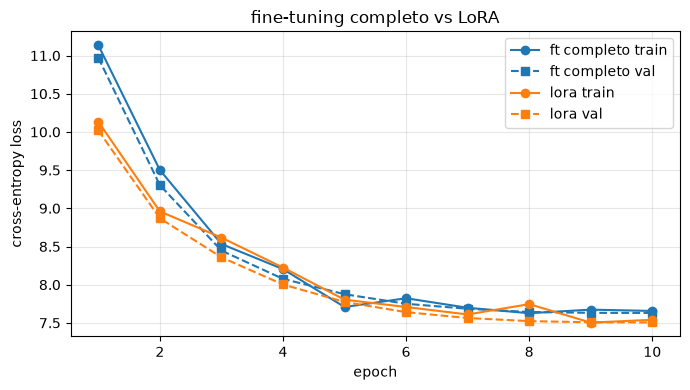

In [15]:
LORA_LR = 1e-3  # LoRA tolera (y necesita) un lr más alto que el fine-tuning completo

# Dos grupos. AdamW aplica decay a todo parámetro que tenga gradiente, y el gradiente del
# embedding enmascarado es cero en vez de ausente -- así que en el grupo por defecto las
# 50.257 filas preentrenadas se encogerían un poco en cada paso, y la Consigna IV mediría
# weight decay, no olvido. param_groups ya pone token_emb y head en el grupo sin decay, que
# es justo lo que las filas enmascaradas necesitan: AdamW aplica decay a lo que tenga
# gradiente, y un gradiente enmascarado es cero y no ausente, así que en el grupo por
# defecto cada fila preentrenada se iría hacia abajo.
opt = AdamW(param_groups(lora_model), lr=LORA_LR)
lora_trainer = Trainer(
    model=lora_model,
    train_data_loader=sft_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt,
    scheduler=cosine_with_warmup(opt, FT_STEPS),
    device=device,
    save_dir="./checkpoints/tp2_lora",
    save_every_n=500,
)

history_lora = run_training(lora_trainer, epochs=FT_EPOCHS)
plot_losses({"ft completo": history_full, "lora": history_lora}, title="fine-tuning completo vs LoRA")

In [16]:
acc_lora_train, acc_lora = evaluate_both(lora_model, "LoRA")

### LoRA
  -- exact match, ejemplos de entrenamiento --


   who_said=2.4% | reverse=0.0% | overall=0.7%
  -- exact match, ejemplos reservados --
   XX  who_said: 'DUKE VINCENTIO'                       esperado 'QUEEN MARGARET'
   XX   reverse: 's'                                    esperado 'nierehw'
   XX   reverse: 's'                                    esperado 'sedivorp'
   XX   reverse: 's'                                    esperado 'deyd'


   who_said=15.1% | reverse=0.0% | overall=5.3%
  brecha: -4.7%


  -- continue (generativa) --
   loss de la respuesta 5.403 | condicionado al prompt 58.3%   (50% = ignora el prompt)
   pide  'continue:  here you sty me\nIn this hard rock, whiles'
   dio   '\nAnd,\nAnd,\nAnd, and the,'
   real  " you do keep from me\nThe rest o' the island"
   pide  'go on:  for the mischance of\nthe hour, if it so'
   dio   ',\nAnd,\nAnd,\nAnd,\nAnd'
   real  ' hap. Cheerly, good hearts! Out\n'
   pide  'what comes next: , bountiful Fortune,\nNow my dear lady, hath'
   dio   ',\nAnd,\nAnd the,\nAnd,\n'
   real  ' mine enemies\nBrought to this shore; and by my'


# Consigna IV — olvido catastrófico

El fine-tuning movió los pesos. ¿Rompió lo que el modelo ya sabía?

Medí la cross-entropy sobre el **conjunto de validación original de Shakespeare** para los tres
modelos (base, fine-tuning completo, LoRA) y generá una continuación de Shakespeare con cada
uno. Notá que esta evaluación no usa template ni tokens especiales — es exactamente el objetivo
de preentrenamiento.

In [17]:
@torch.no_grad()
def shakespeare_loss(model) -> float:
    """
    Cross-entropy media de `model` sobre shakespeare_val_loader.
    """
    model.eval()
    loss_fn = torch.nn.CrossEntropyLoss()
    losses = []
    for x, y in shakespeare_val_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        losses.append(loss_fn(logits.view(-1, logits.size(-1)), y.view(-1)).item())
    return sum(losses) / len(losses)


for name, m in (("base", base_model), ("full ft", full_ft_model), ("lora", lora_model)):
    print(f"{name:>8}: {shakespeare_loss(m):.4f}")


    base: 5.5654


 full ft: 5.3784


    lora: 5.2133


## Preguntas

Ninguna de estas necesita entrenamiento extra.

1. Ordená los tres modelos por loss de Shakespeare y por las métricas de instrucciones. ¿Hay un
   trade-off, y LoRA quedó donde esperabas?
2. Explicá *mecánicamente* por qué restringir el update limita el olvido — ¿qué le puede hacer a
   `W` el fine-tuning completo que LoRA no puede? Si igual LoRA empató con el fine-tuning
   completo acá, ¿qué diría eso sobre el rango intrínseco de esta adaptación, y cuándo dejaría
   de ser cierto?
3. Descongelaste algo más allá de los adapters para que LoRA funcionara siquiera. ¿Qué, por qué
   era inevitable, y qué impidió que se comiera entero el ahorro de parámetros?

---

- Ordenando por loss de Shakespeare, de menor a mayor, quedó LoRA con 5.2133, full ft con 5.3784 y la base con 5.5654, y por accuracy de instrucciones full ft y LoRA empataron en 5.3% en validación mientras la base se quedó en 0.0%. No encontré el trade off que esperaba, donde menos parámetros entrenables signifique peor en la tarea nueva y mejor en la vieja, porque LoRA no solo no olvidó más que el fine tuning completo sino que terminó con menor loss de Shakespeare que él y con la misma accuracy. Como dato aparte, el modelo sin preentrenar de la consigna opcional terminó con la loss de Shakespeare más baja de los cuatro, 4.9367, así que con este corpus tan chico y el replay mezclado durante el fine tuning, esta métrica mide bastante cuánto texto crudo vio el modelo durante el fine tuning, no solo cuánto conservó del preentrenamiento original.
-  El fine tuning completo puede mover cualquier entrada de la matriz W en cualquier dirección porque tiene todos los grados de libertad de esa matriz, así que si el gradiente de la tarea nueva empuja en una dirección que rompe algo aprendido en el preentrenamiento nada se lo impide, mientras que LoRA solo puede sumarle a W una corrección de rango 8, mucho menor que la dimensión real del modelo que es 64, entonces cualquier dirección fuera de ese subespacio de rango 8 queda directamente fuera de su alcance. Que LoRA haya empatado o superado al fine tuning completo en esta corrida me dice que la corrección que esta tarea necesita vive en un subespacio de rango bajo, probablemente igual o menor a 8 para este modelo y esta tarea, y eso dejaría de cumplirse con una tarea mucho más alejada de lo que el modelo vio en el preentrenamiento, donde el update necesario probablemente exceda lo que un adapter de rango 8 puede ofrecer y debería aparecer una brecha a favor del fine tuning completo que acá no vi.
- Tuve que descongelar las filas de token_emb y head correspondientes al vocabulario que usa el SFT, son 13606 de 50261 filas, el 26.72% de los parámetros que realmente pueden moverse, y era inevitable porque resize_token_embeddings agrega los 4 tokens del template con inicialización al azar, y un embedding congelado no recibe ningún gradiente, entonces el modelo nunca podría aprender a emitir el token de fin ni buena parte del vocabulario de las respuestas por más entrenados que estén los adapters. Lo que evitó que esto se comiera todo el ahorro de parámetros fue enmascarar el gradiente fila por fila en vez de descongelar las dos matrices completas, así terminé tocando 26.72% de los parámetros en vez del 98.44% que hubiera tocado descongelando todo el vocabulario.

# la consigna opcional — ¿el preentrenamiento sirvió de algo?

Todo lo de arriba asume que el modelo preentrenado era un buen punto de partida. Probalo.

Entrená un TinyGPT **inicializado al azar** del mismo tamaño solo con los datos de instrucciones,
con el mismo schedule, y compará las curvas de loss y la accuracy contra el modelo fine-tuneado.

Después respondé: la brecha que encuentres, ¿es de *conocimiento* (el modelo ya sabe el alfabeto
y qué letras siguen a cuáles) o de *optimización* (los pesos preentrenados simplemente están en
una cuenca mejor)? Proponé un experimento que separe las dos cosas.

aleatorio (sin preentrenar): 6,535,552 parameters | 6,535,552 trainable (100.00%)
mixed precision: off



  0%|          | 0/401 [00:00<?, ?it/s]


  0%|          | 2/401 [00:00<00:21, 18.67it/s]


  1%|          | 5/401 [00:00<00:21, 18.39it/s]


  2%|▏         | 7/401 [00:00<00:33, 11.78it/s]

...


val_loss 6.76106:  94%|█████████▍| 48/51 [00:02<00:00, 23.25it/s]


val_loss 6.13392:  94%|█████████▍| 48/51 [00:02<00:00, 23.25it/s]


val_loss 6.13392: 100%|██████████| 51/51 [00:02<00:00, 23.19it/s]


val_loss 6.13392: 100%|██████████| 51/51 [00:02<00:00, 23.01it/s]

epoch 10/10 | train 6.4489 | val 6.5841


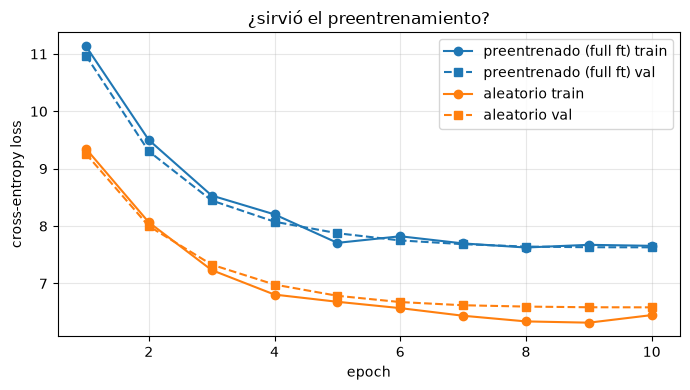

### aleatorio, sin preentrenar
### aleatorio (sin preentrenar)
  -- exact match, ejemplos de entrenamiento --


   who_said=4.8% | reverse=0.0% | overall=1.3%
  -- exact match, ejemplos reservados --
   XX  who_said: 'QUEEN ELIZABETH'                      esperado 'QUEEN MARGARET'
   XX   reverse: 'gnit'                                 esperado 'nierehw'
   XX   reverse: 'gnit'                                 esperado 'sedivorp'
   XX   reverse: 'gnit'                                 esperado 'deyd'


   who_said=5.7% | reverse=0.0% | overall=2.0%
  brecha: -0.7%


  -- continue (generativa) --
   loss de la respuesta 4.892 | condicionado al prompt 75.8%   (50% = ignora el prompt)
   pide  'continue:  here you sty me\nIn this hard rock, whiles'
   dio   ",\nAnd I have, I'll the king,\n"
   real  " you do keep from me\nThe rest o' the island"
   pide  'go on:  for the mischance of\nthe hour, if it so'
   dio   ",\nAnd I am, and I'll the king,"
   real  ' hap. Cheerly, good hearts! Out\n'
   pide  'what comes next: , bountiful Fortune,\nNow my dear lady, hath'


   dio   ',\nAnd I am the king, I have,\n'
   real  ' mine enemies\nBrought to this shore; and by my'



loss de Shakespeare | preentrenado 5.3784 | aleatorio 4.9367 | base 5.5654


In [18]:
torch.manual_seed(2024)
random_model = TinyGPT(config).to(device)   # misma config (vocab ya resizeado), pesos al azar
describe(random_model, "aleatorio (sin preentrenar)")

opt = AdamW(param_groups(random_model), lr=FT_LR)
random_trainer = Trainer(
    model=random_model,
    train_data_loader=sft_train_loader,
    test_data_loader=sft_val_loader,
    loss_fn=SFTWithAuxLM(lam=AUX_LM_LAMBDA),
    gradient_accumulation_steps=1,
    optimizer=opt,
    scheduler=cosine_with_warmup(opt, FT_STEPS),
    device=device,
    save_dir="./checkpoints/tp2_random",
    save_every_n=500,
)
history_random = run_training(random_trainer, epochs=FT_EPOCHS)
plot_losses({"preentrenado (full ft)": history_full, "aleatorio": history_random},
            title="¿sirvió el preentrenamiento?")

print("### aleatorio, sin preentrenar")
acc_random_train, acc_random = evaluate_both(random_model, "aleatorio (sin preentrenar)")

print(f"\nloss de Shakespeare | preentrenado {shakespeare_loss(full_ft_model):.4f} "
      f"| aleatorio {shakespeare_loss(random_model):.4f} | base {shakespeare_loss(base_model):.4f}")


**Respuesta:**

Con el mismo schedule, el modelo inicializado al azar terminó con menor loss de Shakespeare que el preentrenado, 4.9367 contra 5.3784 de full ft y 5.2133 de LoRA, y con mayor condicionamiento al prompt en continue, 75.8% contra 61.7% y 58.3%, aunque su accuracy de instrucciones quedó más abajo, 2.0% contra 5.3%. Esto sugiere que la brecha es más de optimización que de conocimiento, porque con un corpus tan chico y 25% de replay mezclado en el fine tuning, 10 épocas alcanzan para que hasta un modelo sin preentrenar ajuste bien la distribución objetivo. Donde sí noto la ventaja del preentrenamiento es en que genera con cadencia shakespeariana reconocible desde la primera época, mientras el modelo al azar tiene que aprender esa forma junto con la tarea, y para separar las dos cosas propongo congelar todo el cuerpo preentrenado dejando entrenables solo token_emb y head, y comparar esa variante contra un modelo al azar con esas mismas capas congeladas.

# Consigna V — hablarle

Todo lo de arriba es medición. Esto es el camino de inferencia completo: aplicar el template,
samplear una respuesta, frenar en `<|end|>`.

Ya escribiste casi todo. La Consigna I del TP-1 te dio `generateV2`, con temperatura, top-k,
top-p y el KV-cache. Portalo a `chat()` — faltan tres cosas:

| falta | qué agregar | por qué importa |
|---|---|---|
| no hay condición de parada | cortar cuando el token sampleado sea `END_ID` | el TP-1 siempre llegaba a `max_new_tokens`; un modelo de chat decide cuándo terminó |
| devuelve prompt + completion | devolver solo la respuesta | una respuesta es la respuesta, no el eco de la pregunta |
| no hay supresión de logits | poner los logits de `<\|user\|>`, `<\|assistant\|>` y `<\|pad\|>` en `-inf` | si no, samplea andamiaje de chat en medio de una respuesta |

Dos notas. El TP-1 tipaba el argumento del tokenizer como `CharTokenizer`, pero el de
HuggingFace hace duck-typing sobre `.encode`/`.decode`, así que entra sin cambios. Y **sampleá,
no decodifiques greedy** — greedy está bien para puntuar porque es determinista, pero entra en
loops feos en un modelo así de chico (`and the people, and the people`).

In [ ]:
# TODO: Consigna V
def _top_p_filter(logits: torch.Tensor, top_p: Optional[float]) -> torch.Tensor:
    """Mismo top-p de generateV2 (TP-1), portado acá porque _filter_top_k_top_p vive en ese notebook."""
    if top_p is None:
        return logits
    sorted_logits, sorted_idx = torch.sort(logits, descending=True, dim=-1)
    sorted_probs = F.softmax(sorted_logits, dim=-1)
    cum_probs = torch.cumsum(sorted_probs, dim=-1)

    sorted_remove = cum_probs > top_p
    sorted_remove[..., 1:] = sorted_remove[..., :-1].clone()
    sorted_remove[..., 0] = False

    remove = torch.zeros_like(sorted_remove).scatter(-1, sorted_idx, sorted_remove)
    return logits.masked_fill(remove, float("-inf"))


@torch.no_grad()
def chat(model, message: str, temperature: float = 0.8, top_p: float = 0.9,
         max_new_tokens: int = 24, seed: Optional[int] = None) -> str:
    """
    Un turno: envolver `message` en el chat template, samplear una respuesta, frenar en <|end|>.

    Arranca desde generateV2 del TP-1 -- el sampleo ya está ahí. Lo que se agrega: condición
    de parada en END_ID, devolver solo la respuesta, y suprimir los logits de andamiaje.
    """
    if seed is not None:
        torch.manual_seed(seed)

    model.eval()
    dev = next(model.parameters()).device
    block_size = model.config.block_size

    prompt = f"{USER}{message}{ASSISTANT}"
    idx = torch.tensor(tokenizer.encode(prompt), dtype=torch.long, device=dev)[None, :]
    idx = idx[:, -block_size:]

    # <|end|> NO se suprime -- es justo lo que usamos como condición de parada.
    suppress = torch.tensor(
        [tokenizer.convert_tokens_to_ids(t) for t in (USER, ASSISTANT, PAD)], device=dev)

    kv_cache, produced = None, []

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:] if kv_cache is None else idx[:, -1:]
        logits, kv_cache = model(idx_cond, kv_cache=kv_cache, use_cache=True)
        kv_cache = trim_kv_cache(kv_cache, block_size - 1)

        step_logits = logits[:, -1, :].clone()
        step_logits[:, suppress] = float("-inf")
        step_logits = step_logits / temperature
        step_logits = _top_p_filter(step_logits, top_p)

        probs = F.softmax(step_logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        if int(next_token) == END_ID:
            break
        produced.append(int(next_token))
        idx = torch.cat((idx, next_token), dim=1)

    return tokenizer.decode(produced)


for msg in ("continue: To be, or not to be,",
            "finish this: First Citizen:\nBefore we proceed",
            "who said: Now is the winter of our discontent",
            "reverse: sword"):
    print(f"> {msg}")
    print(f"  {chat(full_ft_model, msg, seed=0)!r}\n")


> continue: To be, or not to be,
  '\nYet? the myT and to the lord.\n\nDUKE VINC'

> finish this: First Citizen:
Before we proceed
  ', and'

> who said: Now is the winter of our discontent
  'DUKE VINCENTIO'

> reverse: sword


  'nS'



# Consigna VI — ¿a qué le presta atención?

La Consigna II mostró que el modelo rutea según la instrucción: la misma entrada con `continue`
y con `reverse` produce respuestas distintas. Esta consigna pregunta *cómo*.

En la posición de `<|assistant|>` — el momento justo antes de comprometerse con el primer token
de la respuesta — ¿a qué tokens le da peso la atención? ¿Al marcador de tarea (`continue`,
`who_said`), o al contenido que viene después?

Visualizaste atención en la Consigna IV del TP-1. `tinygpt.visualize_attention` sigue
funcionando, con una salvedad: llama a `tokenizer.itos[i]`, que un tokenizer de HuggingFace no
tiene. Arreglá esa línea, o imprimí los pesos como tabla.

`model(idx, return_weights=True)` devuelve `(logits, weights)`, donde la entrada de cada capa
tiene forma `(n_head, B, T, T_k)`. Promediá sobre las heads y tomá la última fila de queries.

Reportá a qué mira la posición de la respuesta para un ejemplo de cada tarea, y conectalo con la
accuracy que mediste en la Consigna II.

In [20]:
@torch.no_grad()
def attention_at_answer(model, message: str, layer: int = -1, top: int = 6) -> None:
    """
    Imprime los tokens que más mira la posición <|assistant|>, para un prompt.
    """
    model.eval()
    dev = next(model.parameters()).device
    prompt = f"{USER}{message}{ASSISTANT}"
    ids = tokenizer.encode(prompt)
    idx = torch.tensor(ids, dtype=torch.long, device=dev)[None, :]
    idx = idx[:, -model.config.block_size:]

    _, weights = model(idx, return_weights=True)
    # weights[layer]: (n_head, B, T, T_k) -- promedio sobre heads, última fila de queries
    # (la posición de <|assistant|>, justo antes de comprometerse con el primer token).
    w = weights[layer][:, 0, -1, :].mean(dim=0)

    tokens = [tokenizer.decode([i]) for i in idx[0].tolist()]
    top_idx = torch.topk(w, min(top, w.numel())).indices.tolist()

    print(f"> {message!r}")
    for i in sorted(top_idx, key=lambda i: -w[i]):
        print(f"   {w[i].item():5.1%}  pos {i:>2}  {tokens[i].replace(chr(10), chr(92)+'n')!r}")
    print()


for m in ("continue: To be, or not to be,", "who said: Now is the winter",
          "reverse: sword"):
    attention_at_answer(full_ft_model, m)


> 'continue: To be, or not to be,'
   27.3%  pos  1  'continue'
   25.0%  pos 11  '<|assistant|>'
    9.4%  pos  9  ' be'
    7.6%  pos  6  ' or'
    6.6%  pos 10  ','
    5.4%  pos  4  ' be'

> 'who said: Now is the winter'
   41.8%  pos  8  '<|assistant|>'
   22.3%  pos  1  'who'
   12.2%  pos  6  ' the'
    8.5%  pos  3  ':'
    4.0%  pos  0  '<|user|>'
    3.6%  pos  5  ' is'

> 'reverse: sword'
   47.0%  pos  4  '<|assistant|>'
   17.6%  pos  0  '<|user|>'
   16.2%  pos  2  ':'
   15.4%  pos  3  ' sword'
    3.9%  pos  1  'reverse'



En continue la atención se reparte entre el marcador continue con 27.3% y la posición de assistant con 25.0%, en who said domina assistant con 41.8% seguido del marcador who con 22.3%, y en reverse domina aún más assistant con 47.0% seguido de user con 17.6% y de la palabra a invertir con 15.4%, mientras el marcador reverse en sí recibe apenas 3.9%. Esto coincide con la accuracy que medí en la Consigna II, el modelo sí rutea y produce patrones de atención distintos por tarea, con peso real sobre el marcador en continue y who said, pero en reverse, la tarea que peor le va, le presta mucha más atención a la palabra en sí que al nombre de la tarea, como si tratara de copiarla sin haber aprendido qué pide la instrucción, lo que sugiere que buena parte de lo que el modelo sabe en esa posición ya está en su estado oculto antes de esta capa, más que recuperado por atención acá.

# ¿El modelo sigue sano?

La accuracy no es lo único que vale la pena medir. Un modelo que saca 0% pero emite respuestas
bien formadas y que terminan sigue siendo un generador que funciona; uno que emite `!` para
siempre, no, diga lo que diga su loss.

Dos propiedades: las respuestas **frenan solas** en `<|end|>`, y el modelo **sigue siendo un
modelo de lenguaje** — loss de preentrenamiento cerca de la del modelo base.

In [21]:
@torch.no_grad()
def generation_health(model, name: str, n: int = 60) -> None:
    """¿Termina, y sigue siendo un modelo de lenguaje? No es accuracy."""
    lengths = [len(tokenizer.encode(generate_until(model, format_example(ex)[0])))
               for ex in val_examples[:n]]
    stopped = sum(1 for L in lengths if L < 24)      # 24 es el tope de generate_until
    print(f"{name:>9} | {100 * stopped / n:>9.1f}% | {sum(lengths) / n:>9.1f} | "
          f"{shakespeare_loss(model):>10.3f}")


print(f"{'modelo':>9} | {'termina':>10} | {'largo med':>9} | {'loss lm':>10}")
print("-" * 48)
for nm, m in (("base", base_model), ("full ft", full_ft_model), ("lora", lora_model)):
    generation_health(m, nm)

ex = next(e for e in val_examples if e[0] == "continue")
print(f"\nrespuesta de ejemplo a {format_example(ex)[0]!r}:")
print(f"  {generate_until(full_ft_model, format_example(ex)[0], max_new_tokens=20)!r}")
print("\nSano = termina solo Y mantiene la loss de lm cerca de la del modelo base.")

   modelo |    termina | largo med |    loss lm
------------------------------------------------


     base |       0.0% |      24.0 |      5.565


  full ft |     100.0% |       4.1 |      5.378


     lora |     100.0% |       5.8 |      5.213

respuesta de ejemplo a '<|user|>continue:  here you sty me\nIn this hard rock, whiles<|assistant|>':
  '\nAnd'

Sano = termina solo Y mantiene la loss de lm cerca de la del modelo base.


# ⚠️ Guardá tus checkpoints

`Trainer` escribe `checkpoint_final.pt` al final de cada época, así que una corrida completa ya
dejó estos archivos en tu máquina:

```
./checkpoints/tp2_full_ft/checkpoint_final.pt
./checkpoints/tp2_lora/checkpoint_final.pt
```

**No los entregás — simplemente no los borres.** El TP-3 continúa desde el modelo que
fine-tuneaste acá en vez de entrenar uno nuevo. Si vaciás `./checkpoints/` vas a tener que
correr de nuevo las Consignas II y III, que es casi todo el tiempo de ejecución de este
notebook.

Corré la celda de abajo antes de terminar, y asegurate de que las dos líneas digan `ok`.

In [22]:
import os

print("archivos desde los que va a continuar el TP-3 -- guardalos localmente:\n")
missing = 0
for p in ("./checkpoints/tp2_full_ft/checkpoint_final.pt",
          "./checkpoints/tp2_lora/checkpoint_final.pt"):
    exists = os.path.exists(p)
    missing += not exists
    size = f"{os.path.getsize(p) / 1e6:>6.0f} MB" if exists else "     FALTA"
    print(f"  [{'ok' if exists else '!!'}] {p:<46} {size}")

print("\nguardá este directorio -- el TP-3 continúa desde acá en vez de reentrenar."
      if not missing else
      "\ncorré las Consignas II y III hasta el final antes de pasar al TP-3.")


archivos desde los que va a continuar el TP-3 -- guardalos localmente:

  [ok] ./checkpoints/tp2_full_ft/checkpoint_final.pt      78 MB
  [ok] ./checkpoints/tp2_lora/checkpoint_final.pt         78 MB

guardá este directorio -- el TP-3 continúa desde acá en vez de reentrenar.


# Conclusiones

- El objetivo supervisado más el término de replay funcionó, el modelo aprendió a rutear según la instrucción sin perder su capacidad de modelo de lenguaje, la loss de Shakespeare quedó igual o mejor que la del modelo base y los dos terminan de generar solos en el 100% de los casos.

- who said fue la única tarea de exact match que despegó claramente del azar, 15.1% contra 3.5% de baseline de mayoría.

- reverse se quedó en 0.0% en los tres modelos, tal como esperaba por cómo el tokenizer BPE rompe la tarea.

- LoRA, con 26.72% de los parámetros realmente entrenables, igualó la accuracy del fine tuning completo y terminó con menor loss de Shakespeare, restringir el update a rango 8 no me costó nada medible.

- Lo más raro lo encontré en la consigna opcional, el modelo inicializado al azar terminó con la loss de Shakespeare más baja de los cuatro, 4.94, y con el mayor condicionamiento al prompt en continue, 75.8%, lo que sugiere que a esta escala la ventaja real del preentrenamiento está más del lado de la optimización que del conocimiento que mide esta loss puntual.


# ¡Felicitaciones! 🎉

A lo largo de dos notebooks preentrenaste un GPT, implementaste las estrategias de decodificación
que lo convierten en un generador de texto, lo hiciste sparse con una Mixture of Experts, y lo
alineaste a una tarea con fine-tuning completo y con LoRA.

Ese es el pipeline moderno completo de una LLM, a una escala que podés leer de punta a punta.